Scratch KNN accuracy: 0.9473684210526315
Without scaling accuracy: 0.956140350877193
With scaling accuracy: 0.9473684210526315
Best k: 9
Best test accuracy: 0.9649122807017544


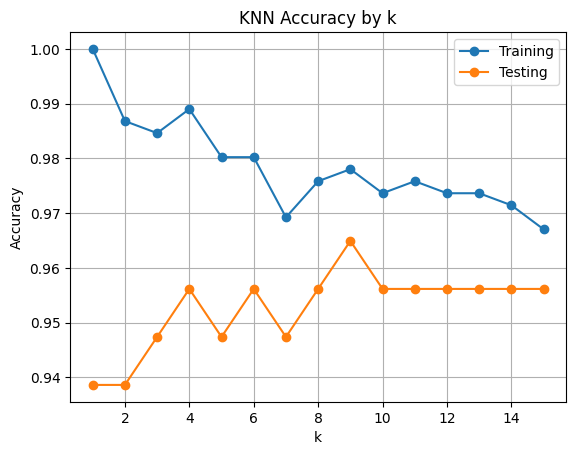

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load and split the data
X, y = load_breast_cancer(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# KNN implemented from scratch
def knn_predict(X_train, y_train, X_test, k=5):
    predictions = []

    for point in X_test:
        distances = np.linalg.norm(X_train - point, axis=1)
        nearest = np.argsort(distances)[:k]

        predictions.append(
            Counter(y_train[nearest]).most_common(1)[0][0]
        )

    return np.array(predictions)


scratch_pred = knn_predict(
    X_train_scaled, y_train, X_test_scaled
)

print("Scratch KNN accuracy:",
      accuracy_score(y_test, scratch_pred))

# Compare with and without scaling
for name, train, test in [
    ("Without scaling", X_train, X_test),
    ("With scaling", X_train_scaled, X_test_scaled),
]:
    model = KNeighborsClassifier(n_neighbors=5).fit(
        train, y_train
    )

    print(
        f"{name} accuracy:",
        accuracy_score(y_test, model.predict(test))
    )

# Compare different values of k
ks = range(1, 16)
train_scores, test_scores = [], []

for k in ks:
    model = KNeighborsClassifier(
        n_neighbors=k
    ).fit(X_train_scaled, y_train)

    train_scores.append(
        accuracy_score(
            y_train, model.predict(X_train_scaled)
        )
    )

    test_scores.append(
        accuracy_score(
            y_test, model.predict(X_test_scaled)
        )
    )

best_k = list(ks)[np.argmax(test_scores)]

print("Best k:", best_k)
print("Best test accuracy:", max(test_scores))

plt.plot(ks, train_scores, marker="o", label="Training")
plt.plot(ks, test_scores, marker="o", label="Testing")

plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy by k")
plt.legend()
plt.grid()
plt.show()